# Exploratory Data Analysis (EDA) & Validasi Pola Bisnis Yaboo Kopi
**Tim Capstone A26-CS216 | PIC Data Science 3 (`@elen`)**

Notebook ini memvalidasi distribusi transaksi POS (`1.333` transaksi) dan dataset fitur harian (`135` hari operasional) untuk mendukung analisis Kecerdasan Bisnis dan desain Chart UI.

**1. Memuat & Memeriksa Struktur Data Per Struk

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset per struk
df_trx = pd.read_csv('synthetic_pos_yaboo_1200.csv')

print(f"Total Baris Transaksi: {len(df_trx):,} baris")
display(df_trx.head())

Total Baris Transaksi: 1,286 baris


,transaction_id,tanggal,jam,nama_pelanggan,no_hp_pelanggan,nama_produk,qty,harga_satuan,total_transaksi,metode_bayar,pakai_kopi_gr,pakai_susu_ml,pakai_sirup_ml
0,TRX-10001,2026-07-01,08:05:37,Nadia,8.124123e+10,Palm Sugar Latte,1,22000,22000,QRIS,18,130,25
1,TRX-10002,2026-07-01,12:01:35,NaN,NaN,Es Kopi Susu Yaboo,2,18000,36000,QRIS,36,240,40
2,TRX-10003,2026-07-01,13:28:37,Fajar,8.126672e+10,Es Kopi Susu Yaboo,3,18000,54000,QRIS,54,360,60
3,TRX-10004,2026-07-01,18:09:13,Aulia,8.126099e+10,Matcha / Chocolate Latte,1,20000,20000,QRIS,0,150,15
4,TRX-10005,2026-07-01,19:54:22,NaN,NaN,Americano Arabika,2,15000,30000,QRIS,36,0,0


## 1. Membuat Visualisasi Grafik Menu Terlaris & Kontribusi Omset (Bar Chart)

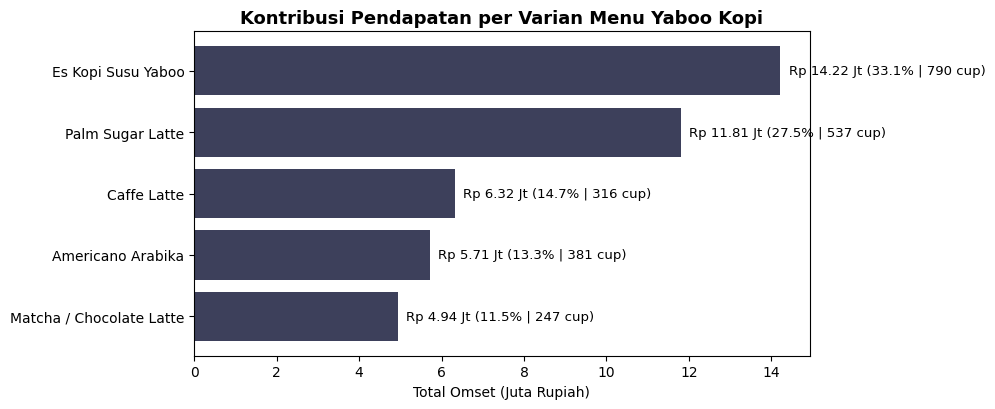

In [10]:
menu_summary = (
    df_trx.groupby('nama_produk', as_index=False)
    .agg(total_cup=('qty', 'sum'), total_omset=('total_transaksi', 'sum'))
    .sort_values('total_omset', ascending=True)
)
menu_summary['persen_omset'] = (menu_summary['total_omset'] / menu_summary['total_omset'].sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 4.2))
bars = ax.barh(menu_summary['nama_produk'], menu_summary['total_omset'] / 1_000_000, color='#3D405B')
ax.set_title('Kontribusi Pendapatan per Varian Menu Yaboo Kopi', fontsize=13, fontweight='bold')
ax.set_xlabel('Total Omset (Juta Rupiah)')
for bar, pct, cup in zip(bars, menu_summary['persen_omset'], menu_summary['total_cup']):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2, f'Rp {bar.get_width():.2f} Jt ({pct}% | {cup} cup)', va='center', fontsize=9.5)
plt.tight_layout()
plt.savefig('eda_charts/03_pareto_menu_terlaris.png')
plt.show()

## 2. Membuat Analisis Jam Sibuk (Hourly Chart) & Metode Pembayaran

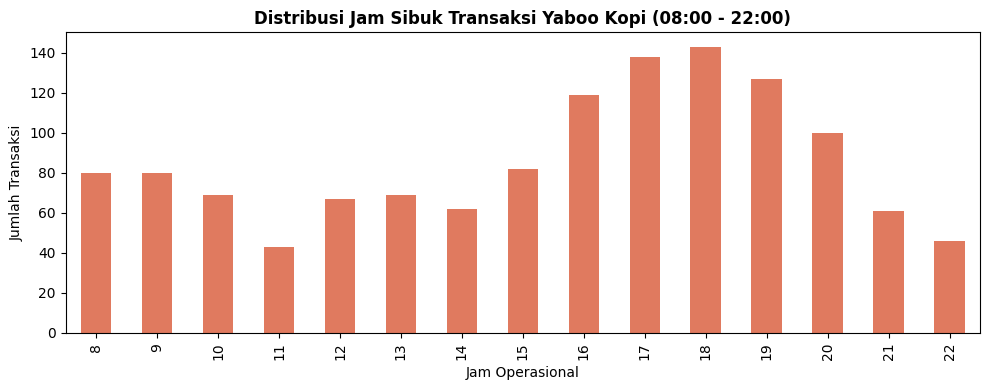

Distribusi Metode Pembayaran:
metode_bayar
QRIS        53.888025
Tunai       35.458787
Transfer    10.653188
Name: proportion, dtype: float64


In [11]:
# Ekstrak jam transaksi (misal format '14:30:00' diambil jamnya saja)
df_trx['jam_transaksi'] = pd.to_datetime(df_trx['jam'], format='%H:%M:%S', errors='coerce').dt.hour

# Grafik Jam Sibuk
hourly_summary = df_trx.groupby('jam_transaksi')['transaction_id'].count()
fig, ax = plt.subplots(figsize=(10, 4))
hourly_summary.plot(kind='bar', color='#E07A5F', ax=ax)
ax.set_title('Distribusi Jam Sibuk Transaksi Yaboo Kopi (08:00 - 22:00)', fontsize=12, fontweight='bold')
ax.set_xlabel('Jam Operasional')
ax.set_ylabel('Jumlah Transaksi')
plt.tight_layout()
plt.savefig('eda_charts/05_jam_sibuk_transaksi.png')
plt.show()

# Ringkasan Metode Pembayaran
print("Distribusi Metode Pembayaran:")
print(df_trx['metode_bayar'].value_counts(normalize=True) * 100)

1. Menjalankan Fungsi Agregasi Finansial Harian

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset agregasi harian
df_daily = pd.read_csv('../data/processed/05_yaboo_stok_harian_ml_ready.csv')
df_daily['tanggal'] = pd.to_datetime(df_daily['tanggal'])

# Agregasi Finansial Utama
total_akumulatif = df_daily['total_omset_idr'].sum()
rata_rata_omset = df_daily['total_omset_idr'].mean()
hari_tertinggi = df_daily.loc[df_daily['total_omset_idr'].idxmax()]
hari_terendah = df_daily.loc[df_daily['total_omset_idr'].idxmin()]

print("=== RINGKASAN AGREGASI FINANSIAL HARIAN ===")
print(f"Total Omset Akumulatif (135 Hari) : Rp {total_akumulatif:,}")
print(f"Rata-Rata Omset Harian           : Rp {rata_rata_omset:,.2f}")
print(f"Omset Tertinggi Terjadi Pada     : {hari_tertinggi['tanggal'].date()} (Rp {hari_tertinggi['total_omset_idr']:,})")
print(f"Omset Terendah Terjadi Pada      : {hari_terendah['tanggal'].date()} (Rp {hari_terendah['total_omset_idr']:,})")

=== RINGKASAN AGREGASI FINANSIAL HARIAN ===
Total Omset Akumulatif (135 Hari) : Rp 43,009,000
Rata-Rata Omset Harian           : Rp 318,585.19
Omset Tertinggi Terjadi Pada     : 2026-08-22 (Rp 631,000)
Omset Terendah Terjadi Pada      : 2026-08-20 (Rp 131,000)


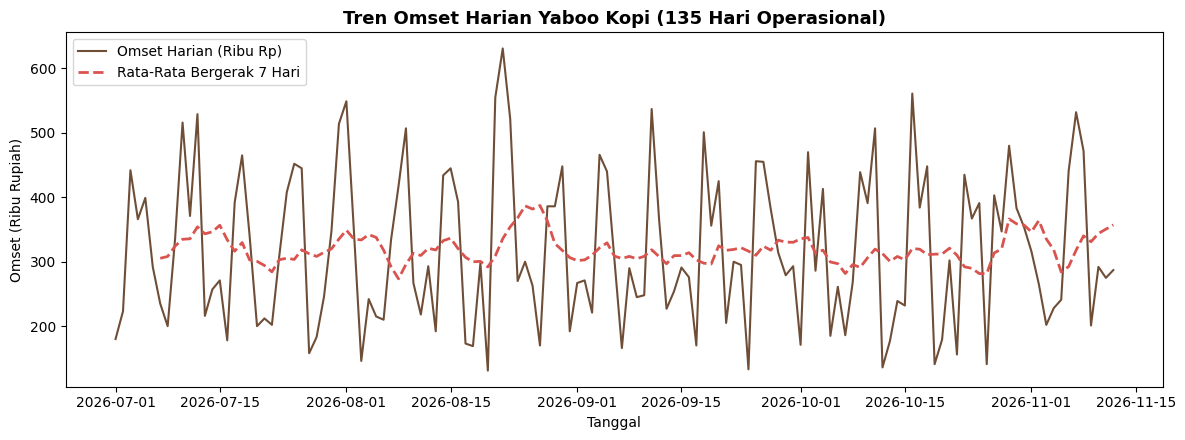

In [13]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(df_daily['tanggal'], df_daily['total_omset_idr'] / 1000, color='#6F4E37', linewidth=1.5, label='Omset Harian (Ribu Rp)')
ax.plot(df_daily['tanggal'], (df_daily['total_omset_idr'].rolling(7).mean()) / 1000, color='#D9534F', linestyle='--', linewidth=2, label='Rata-Rata Bergerak 7 Hari')
ax.set_title('Tren Omset Harian Yaboo Kopi (135 Hari Operasional)', fontsize=13, fontweight='bold')
ax.set_xlabel('Tanggal')
ax.set_ylabel('Omset (Ribu Rupiah)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('eda_charts/01_tren_omset_harian.png')
plt.show()

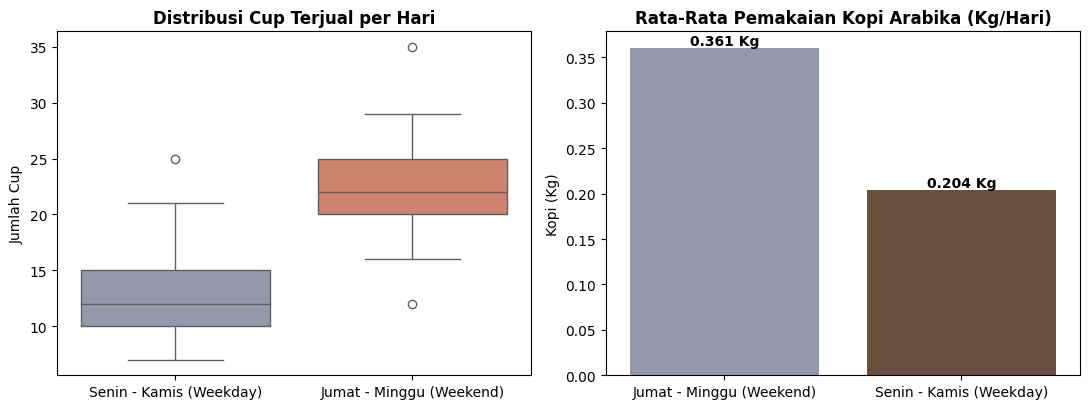

In [14]:
df_daily['tipe_hari'] = df_daily['is_weekend'].map({0: 'Senin - Kamis (Weekday)', 1: 'Jumat - Minggu (Weekend)'})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.boxplot(data=df_daily, x='tipe_hari', y='total_cup_terjual', hue='tipe_hari', legend=False, ax=axes[0], palette=['#8D99AE', '#E07A5F'])
axes[0].set_title('Distribusi Cup Terjual per Hari', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Jumlah Cup')

avg_weekend = df_daily.groupby('tipe_hari', observed=False)['kopi_kg'].mean().reset_index()
sns.barplot(data=avg_weekend, x='tipe_hari', y='kopi_kg', hue='tipe_hari', legend=False, ax=axes[1], palette=['#8D99AE', '#6F4E37'])
axes[1].set_title('Rata-Rata Pemakaian Kopi Arabika (Kg/Hari)', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Kopi (Kg)')
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.3f} Kg', (p.get_x() + p.get_width()/2., p.get_height()), ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('eda_charts/02_perbandingan_weekday_weekend.png')
plt.show()

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset pelatihan deret waktu (Dataset 3)
df_train = pd.read_csv('../data/processed/02_yaboo_stok_harian_latih.csv')
if 'tanggal' in df_train.columns:
    df_train['tanggal'] = pd.to_datetime(df_train['tanggal'])

print(f"Total Baris & Kolom Dataset 3: {df_train.shape}")
display(df_train[['is_payday', 'susu_karton', 'sirup_botol', 'target_kopi_kg_7d']].head())

Total Baris & Kolom Dataset 3: (128, 43)


,is_payday,susu_karton,sirup_botol,target_kopi_kg_7d
0,1,0.083,0.160,1.836
1,1,0.118,0.175,2.016
2,1,0.190,0.365,2.106
3,1,0.216,0.245,2.178
4,1,0.197,0.285,2.178


1. Visualisasi Analisis Efek Tanggal Gajian

C:\Users\HP\AppData\Local\Temp\ipykernel_28020\1881246605.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Hari Biasa (Non-Payday)', 'Periode Gajian (25 - 5)'])


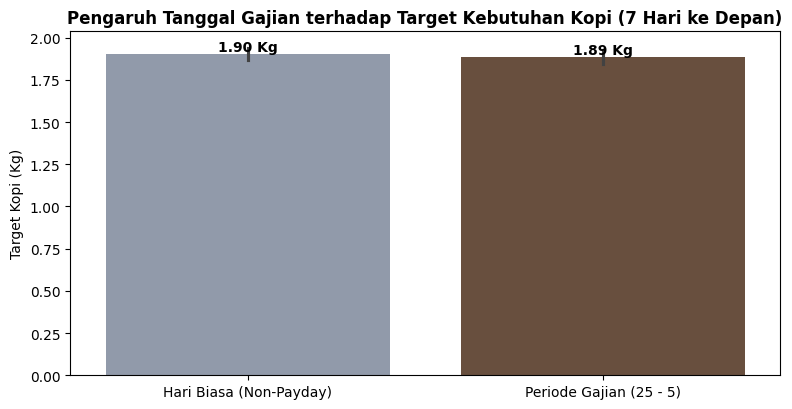

In [16]:
# Pastikan kolom total_omset_idr ada, jika tidak ambil dari gabungan atau kolom target
if 'is_payday' in df_train.columns:
    # Jika total_omset tidak ada di df_train, kita hubungkan dari df_daily atau gunakan kolom yang tersedia
    payday_summary = df_train.groupby('is_payday').mean(numeric_only=True).reset_index()
    
    fig, ax = plt.subplots(figsize=(8, 4.2))
    # Contoh visualisasi target kebutuhan kopi berdasarkan status payday
    sns.barplot(data=df_train, x='is_payday', y='target_kopi_kg_7d', hue='is_payday', legend=False, palette=['#8D99AE', '#6F4E37'], ax=ax)
    ax.set_xticklabels(['Hari Biasa (Non-Payday)', 'Periode Gajian (25 - 5)'])
    ax.set_title('Pengaruh Tanggal Gajian terhadap Target Kebutuhan Kopi (7 Hari ke Depan)', fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Target Kopi (Kg)')
    
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.2f} Kg', (p.get_x() + p.get_width()/2., p.get_height()), ha='center', va='bottom', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.savefig('eda_charts/05_analisis_efek_gajian.png')
    plt.show()

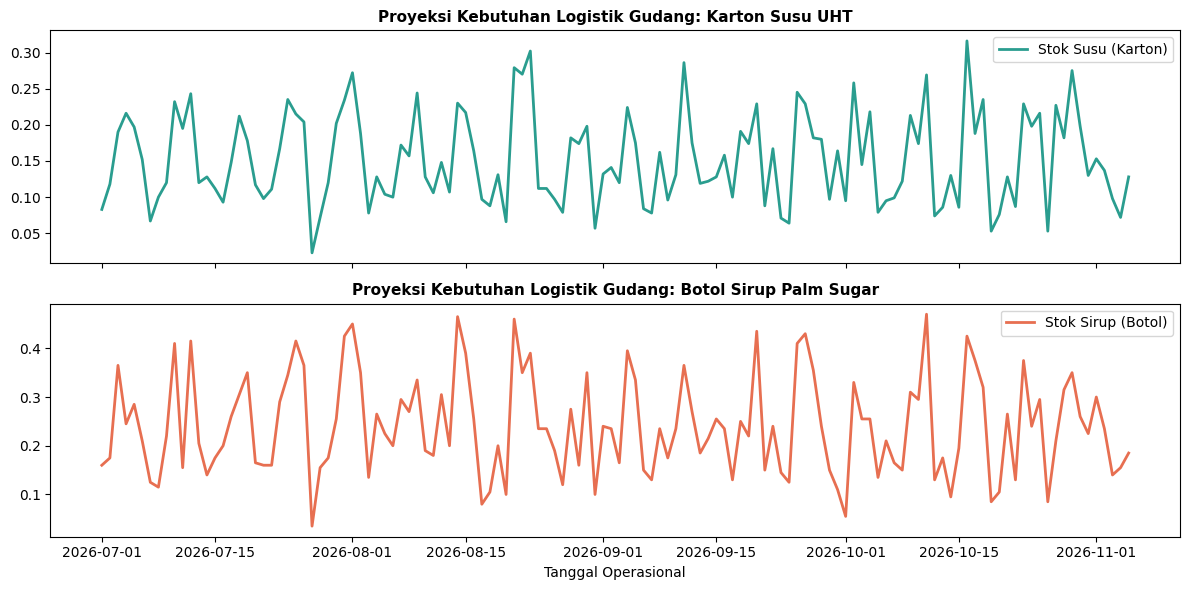

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

if 'susu_karton' in df_train.columns:
    axes[0].plot(df_train['tanggal'], df_train['susu_karton'], color='#2A9D8F', linewidth=2, label='Stok Susu (Karton)')
    axes[0].set_title('Proyeksi Kebutuhan Logistik Gudang: Karton Susu UHT', fontsize=11, fontweight='bold')
    axes[0].legend(loc='upper right')

if 'sirup_botol' in df_train.columns:
    axes[1].plot(df_train['tanggal'], df_train['sirup_botol'], color='#E76F51', linewidth=2, label='Stok Sirup (Botol)')
    axes[1].set_title('Proyeksi Kebutuhan Logistik Gudang: Botol Sirup Palm Sugar', fontsize=11, fontweight='bold')
    axes[1].legend(loc='upper right')
    axes[1].set_xlabel('Tanggal Operasional')

plt.tight_layout()
plt.savefig('eda_charts/06_kebutuhan_kemasan_gudang.png')
plt.show()